
## Partie A : Exploration des données (EAD) et prétraitement du texte

## Préparation

In [ ]:
import sys
sys.path.append("..")

import re
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score

from src.config import RANDOM_STATE, LABEL_NAMES, PROCESSED_DIR
from src.data import load_split, drop_corrupted_rows
from src.cleaning import clean_text, STOPS_ALL, STOPS_KEEP_NEG

sns.set_theme(style="whitegrid")

# 1. Exploration et Analyse des Données (EAD)

## 1.1 Chargement des fichiers

In [ ]:
train = load_split("train")
val = load_split("val")
test = load_split("test")

print("train :", train.shape)
print("val   :", val.shape)
print("test  :", test.shape)

train : (2862, 2)
val   : (955, 2)
test  : (784, 2)


Le train contient 3 lignes corrompues : plusieurs tweets collés sur une même ligne, séparés par des tabulations.
On les supprime dans le train uniquement (validation et test ne sont pas touchés).

In [ ]:
print("Lignes corrompues dans le train :", train["text"].str.contains("\t").sum())

train = drop_corrupted_rows(train)

print("train :", train.shape)
assert len(train) == 2859

Lignes corrompues dans le train : 3
train : (2859, 2)


## 1.2 Analyse des colonnes disponibles

In [ ]:
train.head(10)

,text,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


In [ ]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 2859 entries, 0 to 2858
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    2859 non-null   str  
 1   label   2859 non-null   int64
dtypes: int64(1), str(1)
memory usage: 44.8 KB


In [ ]:
train.describe()

,label
count,2859.000000
mean,0.505421
std,0.500058
min,0.000000
25%,0.000000
50%,1.000000
75%,1.000000
max,1.000000


Le DataFrame a deux colonnes : `text` (le tweet) et `label` (0 = non_irony, 1 = irony), sans valeur manquante.
La moyenne de `label` est proche de 0.5 : les deux classes sont presque équilibrées dans le train.

## 1.3 Distribution des classes (label)

In [ ]:
for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom)
    print(df["label"].value_counts().sort_index())
    print(df["label"].value_counts(normalize=True).sort_index().round(3) * 100)
    print()

train
label
0    1414
1    1445
Name: count, dtype: int64
label
0    49.5
1    50.5
Name: proportion, dtype: float64

val
label
0    499
1    456
Name: count, dtype: int64
label
0    52.3
1    47.7
Name: proportion, dtype: float64

test
label
0    473
1    311
Name: count, dtype: int64
label
0    60.3
1    39.7
Name: proportion, dtype: float64



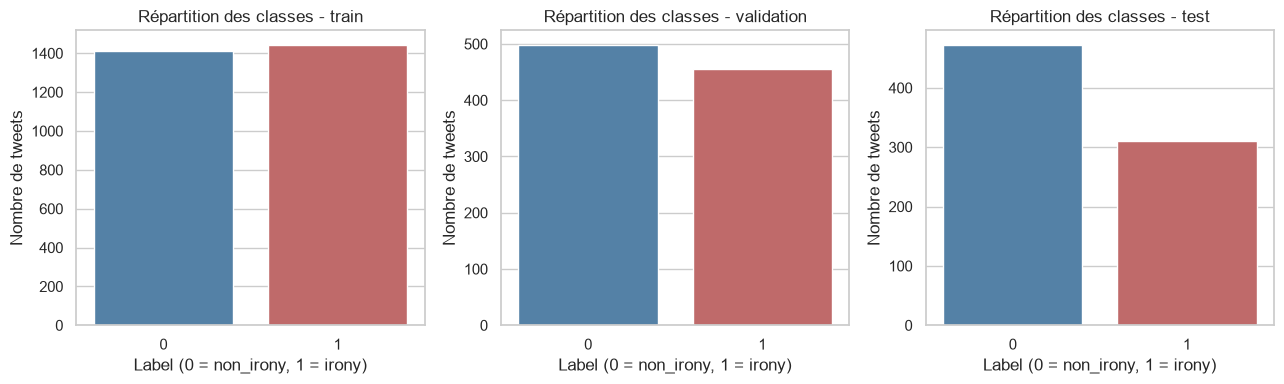

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, nom, df in zip(axes, ["train", "validation", "test"], [train, val, test]):
    sns.countplot(x="label", hue="label", data=df, ax=ax, palette=["steelblue", "indianred"], legend=False)
    ax.set_title("Répartition des classes - " + nom)
    ax.set_xlabel("Label (0 = non_irony, 1 = irony)")
    ax.set_ylabel("Nombre de tweets")

plt.tight_layout()
plt.show()

Le train (1414 non_irony / 1445 irony) et la validation (499 / 456) sont presque équilibrés.
Le test ne l'est pas : 473 tweets non ironiques contre 311 ironiques (environ 60 % / 40 %).
Pour cette raison, on ne se limitera pas à l'accuracy : on utilisera surtout le F1 macro, qui donne le même poids aux deux classes.

## 1.4 Longueur des textes

In [ ]:
train["n_chars"] = train["text"].str.len()
train["n_words"] = train["text"].str.split().str.len()

train[["n_chars", "n_words"]].describe()

,n_chars,n_words
count,2859.000000,2859.000000
mean,78.780693,13.521861
std,32.416796,5.871894
min,6.000000,1.000000
25%,52.000000,9.000000
50%,78.000000,13.000000
75%,106.000000,18.000000
max,141.000000,33.000000


In [ ]:
train.groupby("label")[["n_chars", "n_words"]].mean().round(1)

,n_chars,n_words
label,,
0,79.3,13.5
1,78.2,13.5


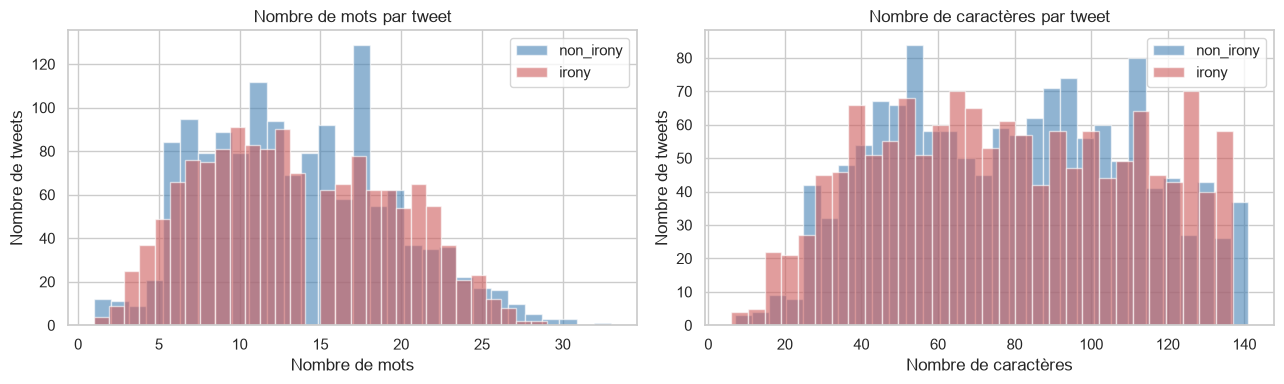

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for col, ax, titre in zip(["n_words", "n_chars"], axes, ["mots", "caractères"]):
    ax.hist(train[train["label"] == 0][col], bins=30, alpha=0.6, label=LABEL_NAMES[0], color="steelblue")
    ax.hist(train[train["label"] == 1][col], bins=30, alpha=0.6, label=LABEL_NAMES[1], color="indianred")
    ax.set_title("Nombre de " + titre + " par tweet")
    ax.set_xlabel("Nombre de " + titre)
    ax.set_ylabel("Nombre de tweets")
    ax.legend()

plt.tight_layout()
plt.show()

Un tweet fait en moyenne 13 à 14 mots (environ 79 caractères), avec un maximum de 33 mots et 141 caractères une fois les lignes corrompues retirées.
Les deux classes ont presque la même longueur (13.5 mots en moyenne dans chaque classe) : la longueur ne permet pas de deviner l'ironie.

## 1.5 WordCloud : mots fréquents par classe

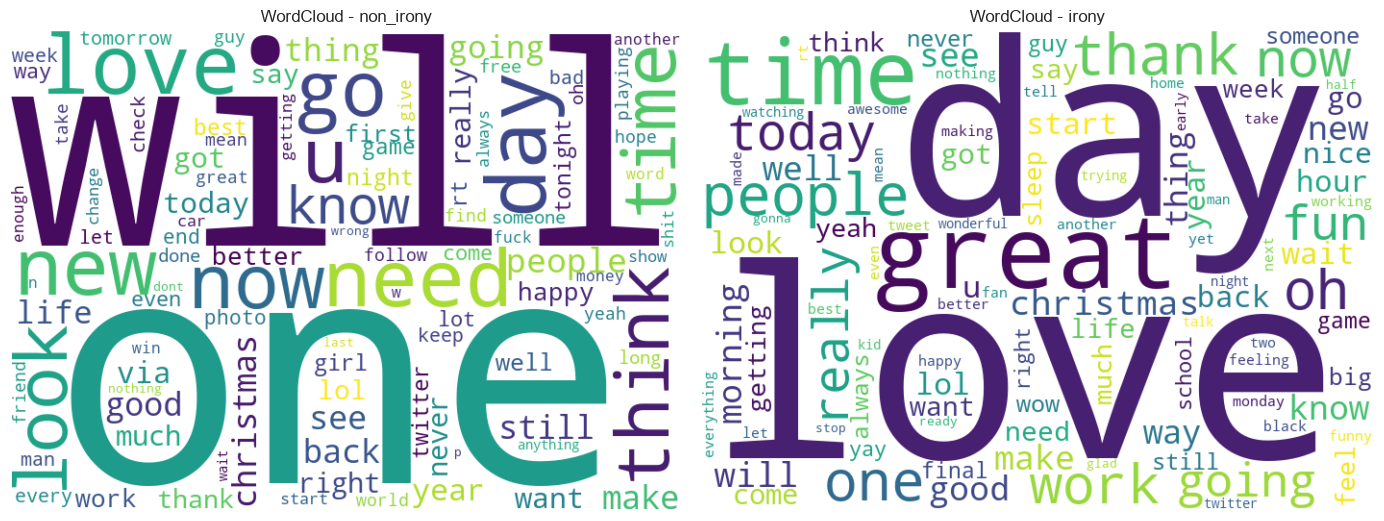

In [ ]:
a_ignorer = set(STOPWORDS) | {"user", "http", "https", "co", "amp"}

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, lab in zip(axes, [0, 1]):
    textes = train[train["label"] == lab]["text"].apply(lambda t: clean_text(t, remove_stopwords=False, remove_punct=False, lemmatize=False))
    nuage = WordCloud(width=700, height=500, background_color="white", stopwords=a_ignorer,
                      max_words=100, random_state=RANDOM_STATE).generate(" ".join(textes))
    ax.imshow(nuage, interpolation="bilinear")
    ax.set_title("WordCloud - " + LABEL_NAMES[lab])
    ax.axis("off")

plt.tight_layout()
plt.show()

Les deux nuages sont différents. Dans la classe irony, on voit surtout des mots positifs (*love*, *great*, *fun*, *thank*, *nice*, *awesome*, *wow*, *yay*).
Dans la classe non_irony, les mots dominants sont plus neutres (*will*, *one*, *new*, *think*, *need*).
Un mot positif apparaît donc plus souvent dans les tweets ironiques, ce qui explique pourquoi l'ironie est difficile à détecter : ces mêmes mots sont aussi utilisés sincèrement.

# 2. Prétraitement du texte

## 2.1 Ce que contiennent les tweets

In [ ]:
pd.set_option("display.max_colwidth", 200)
train[["text", "label"]].sample(8, random_state=RANDOM_STATE)

,text,label
1584,@user doesn't lucky and fortunate mean the same thing?,1
1746,Drinking an Imperial IPA (2014-) by @user - #photo,0
772,I love being on hold. Especially when the music is so great.,1
1729,Look! It's a white Christmas after all! #MinnesotaProblems,1
387,#almajmoua participating in the 4th #CSR forum #lebanon #togetherwegrow -for-profit #microfinance #supporting...,0
407,#UKPLUS= Consists of Free Lebara2Lebara 3000MINs and 3000SMS UNLIMITED. #NO UNLIMITED SMS TO OTHER NETWORK Only consists of 1000SMS,0
2441,"@user oh brother, the bar for journalism is very high these days @user why do you follow such retards?",1
1992,Ariana Grandes makeup is always sooo flawless 🙊,0


In [ ]:
print("Tweets avec une mention (@user) :", train["text"].str.contains("@").sum())
print("Tweets avec un lien (http)      :", train["text"].str.contains("http").sum())
print("Tweets avec un hashtag (#)      :", train["text"].str.contains("#").sum())
print("Total de tweets                 :", len(train))

Tweets avec une mention (@user) : 1164
Tweets avec un lien (http)      : 23
Tweets avec un hashtag (#)      : 1101
Total de tweets                 : 2859


Les mentions sont déjà anonymisées en `@user`. Beaucoup de tweets contiennent une mention ou un hashtag, très peu un lien.

Autre vérification : les hashtags `#not`, `#irony` et `#sarcasm` sont ceux qui ont servi à collecter les tweets ironiques.

In [ ]:
def a_hashtag_ironie(texte):
    hashtags = re.findall(r"#\w+", texte.lower())
    return any(h in hashtags for h in ["#not", "#irony", "#sarcasm"])

for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom, ":", df["text"].apply(a_hashtag_ironie).sum(), "tweets sur", len(df))

dans_test = test[test["text"].apply(a_hashtag_ironie)]
print("Part de tweets irony parmi ceux du test :", round(dans_test["label"].mean(), 2))

train : 0 tweets sur 2859
val : 0 tweets sur 955
test : 431 tweets sur 784
Part de tweets irony parmi ceux du test : 0.72


Aucun tweet du train ni de la validation ne contient ces hashtags , alors que 431 tweets du test sur 784 en contiennent, dont 72 % sont ironiques.
Le test n'a donc pas été préparé comme le train et la validation : les modèles n'ont jamais vu ces hashtags pendant l'entraînement.
On ne modifie rien dans le test, mais il faudra en tenir compte quand on interprétera le score final. Tous nos choix (nettoyage, modèles) se font sur la validation uniquement.

## 2.2 Nos choix de nettoyage

In [ ]:
for mot in ["not", "no", "nor", "don't", "isn't", "never"]:
    print(mot, "->", mot in STOPS_ALL)

print()
print("Stopwords NLTK :", len(STOPS_ALL))
print("Stopwords sans les négations :", len(STOPS_KEEP_NEG))

not -> True
no -> True
nor -> True
don't -> True
isn't -> True
never -> False

Stopwords NLTK : 198
Stopwords sans les négations : 158


La liste de stopwords de NLTK contient des négations (`not`, `no`, `don't`...). Les supprimer change le sens d'un tweet (« not good » devient « good »).
On utilise donc une liste de stopwords **sans les négations**.

Certaines étapes (minuscules, ponctuation `!!!` `...`, stopwords) peuvent aussi supprimer des signaux d'ironie.
Plutôt que de deviner, on teste 5 versions du nettoyage, de plus en plus poussées :
chacune est vectorisée avec TF-IDF, apprise avec une régression logistique sur le **train** et notée sur la **validation** (jamais sur le test).
Le vectorizer garde la ponctuation et les emojis comme des mots (sinon on ne pourrait pas tester l'effet de la ponctuation).

In [ ]:
v1 = dict(remove_links=True, remove_mentions=True, hashtags="keep", lowercase=False,
          remove_stopwords=False, remove_punct=False, lemmatize=False)
v2 = dict(v1, hashtags="strip_symbol", lowercase=True)
v3 = dict(v2, remove_stopwords=True)
v4 = dict(v3, remove_punct=True)
v5 = dict(v4, lemmatize=True)

versions = {
    "V1 liens et mentions retirés": v1,
    "V2 + minuscules, # retiré": v2,
    "V3 + stopwords (négations gardées)": v3,
    "V4 + ponctuation retirée": v4,
    "V5 + lemmatisation": v5,
}

In [ ]:
def tester(params):
    X_train = train["text"].apply(lambda t: clean_text(t, **params))
    X_val = val["text"].apply(lambda t: clean_text(t, **params))

    modele = Pipeline([
        ("tfidf", TfidfVectorizer(token_pattern=r"[\w']+|[^\w\s]", lowercase=False)),
        ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
    ])
    modele.fit(X_train, train["label"])
    pred = modele.predict(X_val)

    return {"accuracy": accuracy_score(val["label"], pred),
            "f1_macro": f1_score(val["label"], pred, average="macro")}

resultats = pd.DataFrame({nom: tester(params) for nom, params in versions.items()}).T.round(4)
resultats

,accuracy,f1_macro
V1 liens et mentions retirés,0.6314,0.6312
"V2 + minuscules, # retiré",0.6178,0.6178
V3 + stopwords (négations gardées),0.6251,0.6247
V4 + ponctuation retirée,0.6241,0.6234
V5 + lemmatisation,0.6147,0.6144


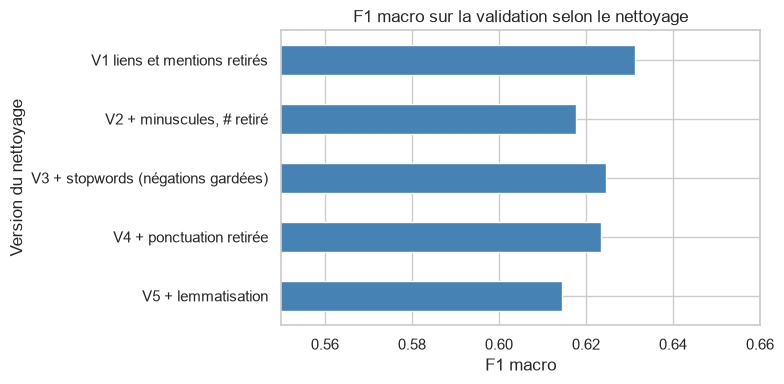

In [ ]:
plt.figure(figsize=(8, 4))
resultats["f1_macro"].iloc[::-1].plot(kind="barh", color="steelblue")
plt.title("F1 macro sur la validation selon le nettoyage")
plt.xlabel("F1 macro")
plt.ylabel("Version du nettoyage")
plt.xlim(0.55, 0.66)
plt.tight_layout()
plt.show()

La version V1 (seulement les liens et les mentions retirés) obtient le meilleur F1 macro sur la validation (0.631).
Passer en minuscules et retirer le `#` (V2) fait baisser le score (0.618), et les étapes suivantes (stopwords, ponctuation, lemmatisation) ne l'améliorent pas : on reste entre 0.614 et 0.625.
Les écarts sont petits (la validation ne contient que 955 tweets, donc une partie peut être du hasard), mais aucune étape de nettoyage ne montre un vrai gain.

**Choix retenu :** V1. Les liens et les mentions sont du bruit sans information, et on garde le reste (majuscules, ponctuation comme `!!!` ou `...`, mots des hashtags, emojis, négations)
car ces éléments peuvent porter le ton d'un tweet ironique et que l'expérience ne montre pas qu'il faut les supprimer.

## 2.3 Création de la colonne `text_clean`

In [ ]:
meilleure = resultats["f1_macro"].idxmax()
config_finale = versions[meilleure]

print("Version retenue :", meilleure)
print(config_finale)

Version retenue : V1 liens et mentions retirés
{'remove_links': True, 'remove_mentions': True, 'hashtags': 'keep', 'lowercase': False, 'remove_stopwords': False, 'remove_punct': False, 'lemmatize': False}


In [ ]:
for df in (train, val, test):
    df["text_clean"] = df["text"].apply(lambda t: clean_text(t, **config_finale))

train[["text", "text_clean", "label"]].head(10)

,text,text_clean,label
0,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,seeing ppl walking w/ crutches makes me really excited for the next 3 weeks of my life,1
1,"look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵","look for the girl with the broken smile, ask her if she wants to stay while, and she will be loved. 💕🎵",0
2,Now I remember why I buy books online @user #servicewithasmile,Now I remember why I buy books online #servicewithasmile,1
3,@user @user So is he banded from wearing the clothes? #Karma,So is he banded from wearing the clothes? #Karma,1
4,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,Just found out there are Etch A Sketch apps. #oldschool #notoldschool,1
5,"Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!","Hey what do you know, one of the witnesses supporting Darren Wilson's story lied! And is racist! Mind blown!",1
6,@user on stage at #flzjingleball at the @user in #Tampa #iheartradio,on stage at #flzjingleball at the in #Tampa #iheartradio,0
7,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,You know it's going to be a great day when you're Garmin resets itself and you spill some cinnamon down yourself #slowclap,1
8,Halfway thorough my workday ... Woooo,Halfway thorough my workday ... Woooo,1
9,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,Would like to thank my nephew for giving me his horrible cold & sore throat etc.. Much appreciated!,1


Un nettoyage peut laisser un texte vide (par exemple un tweet qui ne contient que des mentions), ce qui poserait problème au moment de la vectorisation.

In [ ]:
for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom, ":", (df["text_clean"].str.strip() == "").sum(), "texte(s) vide(s)")

train : 0 texte(s) vide(s)
val : 1 texte(s) vide(s)
test : 0 texte(s) vide(s)


Pour ces tweets, on garde le texte d'origine en minuscules.

In [ ]:
for df in (train, val, test):
    vide = df["text_clean"].str.strip() == ""
    df.loc[vide, "text_clean"] = df.loc[vide, "text"].str.lower().str.strip()

for nom, df in [("train", train), ("val", val), ("test", test)]:
    print(nom, ":", (df["text_clean"].str.strip() == "").sum(), "texte(s) vide(s)")

train : 0 texte(s) vide(s)
val : 0 texte(s) vide(s)
test : 0 texte(s) vide(s)


In [ ]:
print("Avant :", train["text"].str.split().str.len().mean().round(1), "mots en moyenne")
print("Après :", train["text_clean"].str.split().str.len().mean().round(1), "mots en moyenne")

Avant : 13.5 mots en moyenne
Après : 12.9 mots en moyenne


## 2.4 Sauvegarde des fichiers nettoyés

In [ ]:
colonnes = ["text", "text_clean", "label"]

train[colonnes].to_csv(PROCESSED_DIR / "train.csv", index=False)
val[colonnes].to_csv(PROCESSED_DIR / "validation.csv", index=False)
test[colonnes].to_csv(PROCESSED_DIR / "test.csv", index=False)

print("Fichiers sauvegardés ")

Fichiers sauvegardés dans C:\Users\Mrabet manar\Documents\irony-detection\data\processed


In [ ]:
for fichier in ["train", "validation", "test"]:
    d = pd.read_csv(PROCESSED_DIR / (fichier + ".csv"))
    print(fichier, d.shape, "| text_clean manquants :", d["text_clean"].isna().sum())

train (2859, 3) | text_clean manquants : 0
validation (955, 3) | text_clean manquants : 0
test (784, 3) | text_clean manquants : 0
